In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve
from google.colab import drive

from warnings import filterwarnings
filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen=ImageDataGenerator(rescale=1./255,shear_range=0.2,zoom_range=0.2,rotation_range=20,horizontal_flip=True,width_shift_range=0.2,height_shift_range=0.2)
test_datagen=ImageDataGenerator(rescale=1./255)

In [ ]:
train_set=train_datagen.flow_from_directory('/content/drive/MyDrive/CNN/train',target_size=(150,150),batch_size=32,class_mode='binary')
test_set=test_datagen.flow_from_directory('/content/drive/MyDrive/CNN/test',target_size=(150,150),batch_size=32,class_mode='binary',shuffle=False)



Found 5675 images belonging to 2 classes.
Found 1002 images belonging to 2 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten, Conv2D, MaxPooling2D

model=Sequential([
    Conv2D(32,(3,3),activation="relu",input_shape=(150,150,3)),
    MaxPooling2D(2,2),
    Conv2D(64,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Conv2D(128,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(512,activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(256,activation="relu"),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1,activation="sigmoid")
])

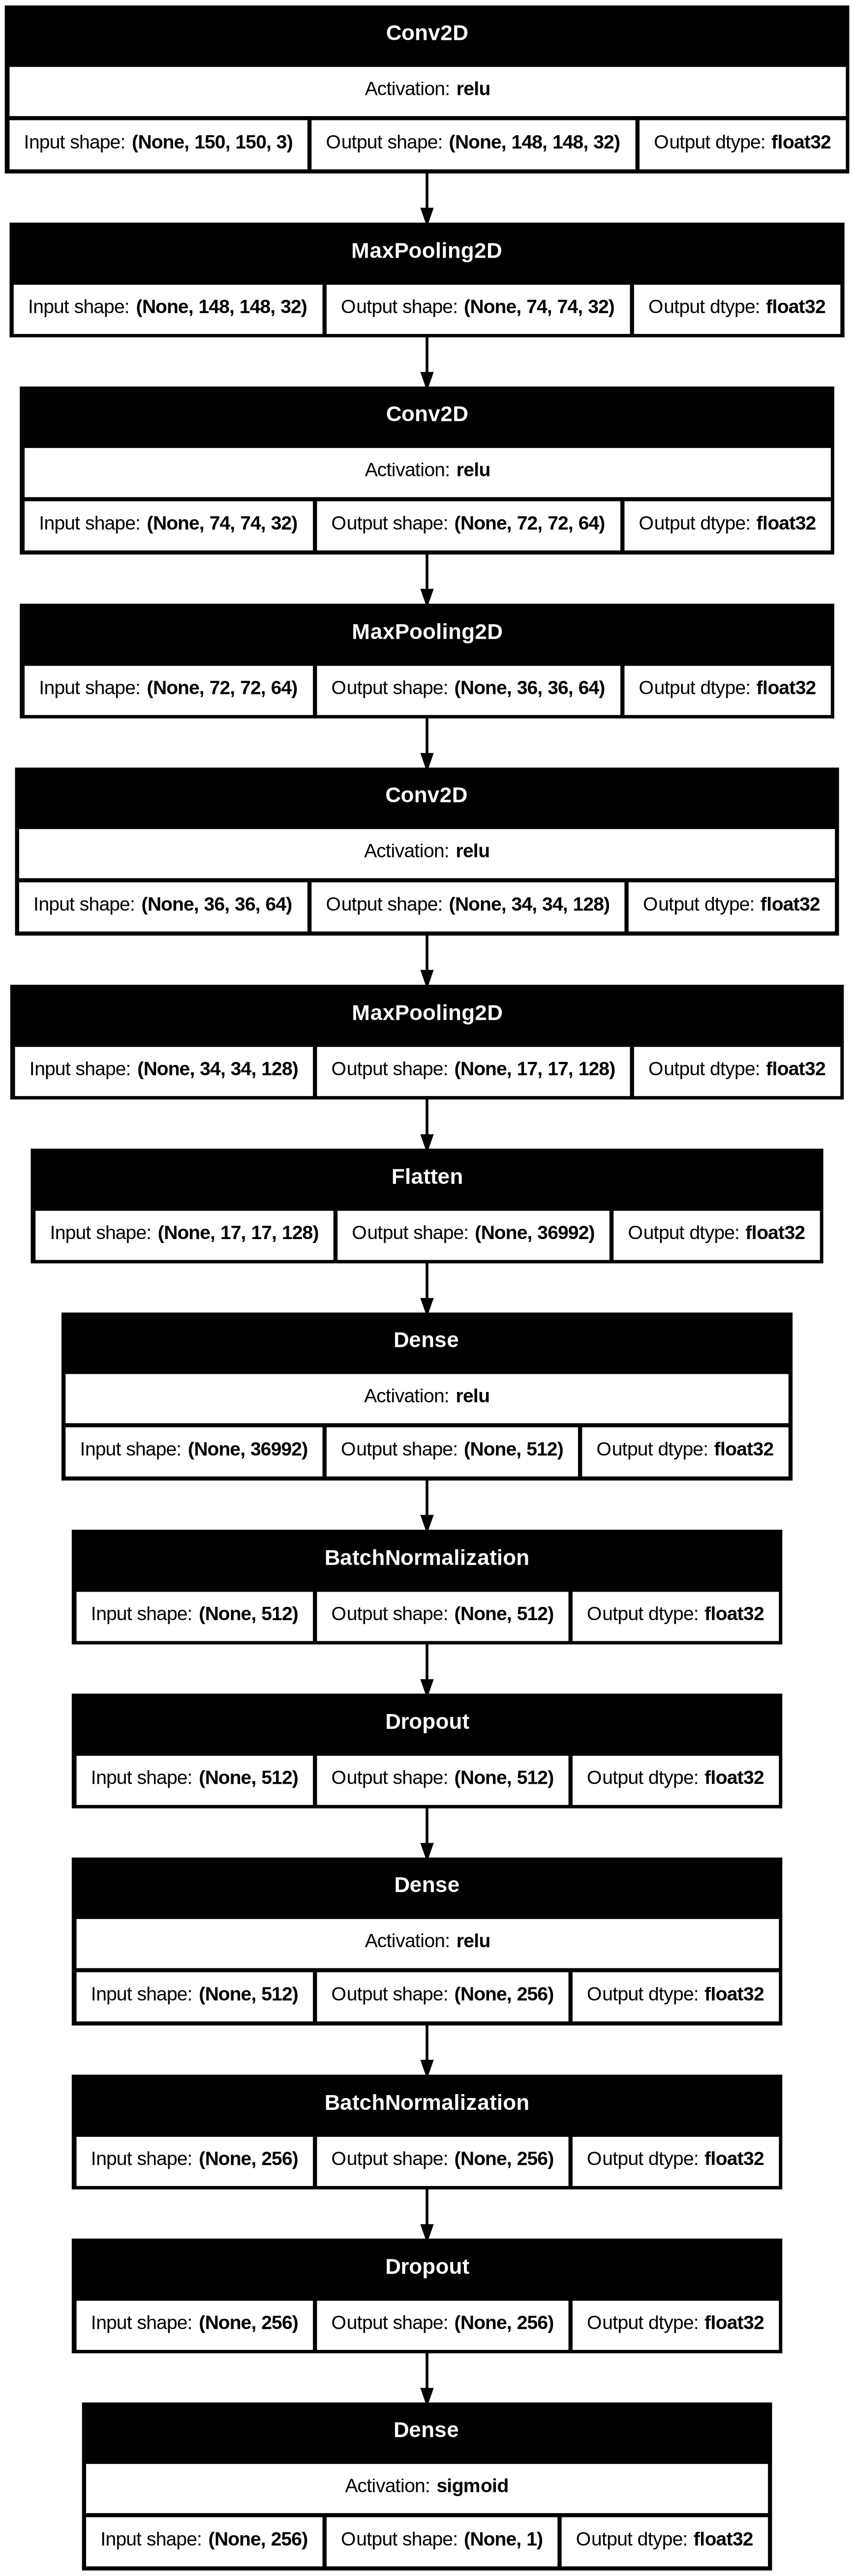

In [ ]:
tf.keras.utils.plot_model(model,show_shapes=True,show_dtype=True,show_layer_activations=True)



In [ ]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])



In [ ]:
early_stopping=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)



In [ ]:
history=model.fit(train_set,epochs=50,validation_data=test_set,callbacks=[early_stopping])



Epoch 1/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 525s 3s/step - accuracy: 0.5822 - loss: 0.8529 - val_accuracy: 0.5429 - val_loss: 0.8218
Epoch 2/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 467s 3s/step - accuracy: 0.6026 - loss: 0.7456 - val_accuracy: 0.5599 - val_loss: 0.7400
Epoch 3/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 456s 3s/step - accuracy: 0.6169 - loss: 0.6762 - val_accuracy: 0.5349 - val_loss: 0.7107
Epoch 4/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 471s 3s/step - accuracy: 0.6402 - loss: 0.6425 - val_accuracy: 0.6467 - val_loss: 0.6259
Epoch 5/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 453s 3s/step - accuracy: 0.6626 - loss: 0.6167 - val_accuracy: 0.5479 - val_loss: 0.7358
Epoch 6/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 451s 3s/step - accuracy: 0.6664 - loss: 0.6024 - val_accuracy: 0.6517 - val_loss: 0.6164
Epoch 7/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 518s 3s/step - accuracy: 0.6925 - loss: 0.5761 - val_accuracy: 0.6287 - val_loss: 0.6256
Epoch 8/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 457s 3s/step - accuracy: 0.6983 - loss: 0.5653 - val_accu

In [ ]:
history_df=pd.DataFrame(history.history)
history_df[['loss','val_loss']].plot(title="Loss vs validation Loss")
history_df[['accuracy','val_accuracy']].plot(title="Accuracy vs validation Accuracy")
accuracy=history.history['accuracy']
print(accuracy)
plt.show()



NameError: name 'history' is not defined

In [ ]:
y_pred=model.predict(test_set)
print(y_pred)
y_true=test_set.classes
fpr,tpr,threshold=roc_curve(y_true,y_pred)
optimal_idx=np.argmax(tpr-fpr)
optimal_threshold=threshold[optimal_idx]
print(f"optimal_threshold:{optimal_threshold}")



32/32 ━━━━━━━━━━━━━━━━━━━━ 180s 6s/step
[[0.49942994]
 [0.4875063 ]
 [0.49578598]
 ...
 [0.49396038]
 [0.4999796 ]
 [0.4937308 ]]
optimal_threshold:0.5112100839614868


In [ ]:
from tensorflow.keras.utils import load_img,img_to_array
def classify_image(image_path,threshold=0.5):
  test_image=load_img(image_path,target_size=(150,150))
  plt.imshow(test_image)
  test_image=img_to_array(test_image)
  test_image=np.expand_dims(test_image,axis=0)
  test_image=test_image / 255.0
  result=model.predict(test_image)[0][0]
  print(f"predicted probability:{result}")

  if result>=threshold:
    prediction='cat'
  else:
    prediction='dog'
  print(f"predicted Label:{prediction}")
  return prediction
classify_image(r'/content/9518.jpg',threshold=optimal_threshold)

NameError: name 'optimal_threshold' is not defined

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve
from google.colab import drive

from warnings import filterwarnings
filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

train_datagen=ImageDataGenerator(rescale=1./255,shear_range=0.2,zoom_range=0.2,rotation_range=20,horizontal_flip=True,width_shift_range=0.2,height_shift_range=0.2)
test_datagen=ImageDataGenerator(rescale=1./255)

train_set=train_datagen.flow_from_directory('/content/drive/MyDrive/CNN/train',target_size=(150,150),batch_size=32,class_mode='binary')
test_set=test_datagen.flow_from_directory('/content/drive/MyDrive/CNN/test',target_size=(150,150),batch_size=32,class_mode='binary',shuffle=False)

model=Sequential([
    Conv2D(32,(3,3),activation="relu",input_shape=(150,150,3)),
    MaxPooling2D(2,2),
    Conv2D(64,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Conv2D(128,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(512,activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(256,activation="relu"),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1,activation="sigmoid")
])

tf.keras.utils.plot_model(model,show_shapes=True,show_dtype=True,show_layer_activations=True)

model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

early_stopping=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

history=model.fit(train_set,epochs=50,validation_data=test_set,callbacks=[early_stopping])

history_df=pd.DataFrame(history.history)
history_df[['loss','val_loss']].plot(title="Loss vs validation Loss")
history_df[['accuracy','val_accuracy']].plot(title="Accuracy vs validation Accuracy")
accuracy=history.history['accuracy']
print(accuracy)
plt.show()

y_pred=model.predict(test_set)
print(y_pred)
y_true=test_set.classes
fpr,tpr,threshold=roc_curve(y_true,y_pred)
optimal_idx=np.argmax(tpr-fpr)
optimal_threshold=threshold[optimal_idx]
print(f"optimal_threshold:{optimal_threshold}")

from tensorflow.keras.utils import load_img,img_to_array
def classify_image(image_path,threshold=0.5):
  test_image=load_img(image_path,target_size=(150,150))
  plt.imshow(test_image)
  test_image=img_to_array(test_image)
  test_image=np.expand_dims(test_image,axis=0)
  test_image=test_image / 255.0
  result=model.predict(test_image)[0][0]
  print(f"predicted probability:{result}")

  if result>=threshold:
    prediction='cat'
  else:
    prediction='dog'
  print(f"predicted Label:{prediction}")
  return prediction
  classify_image(r'/content/9518.jpg',threshold=optimal_threshold)